# Noise and Noisy Simulation

This notebook explores how noise affects quantum circuits and how device characteristics can be used to construct noisy simulations.

We will:

- Create a scalable GHZ circuit
- Run it on an ideal simulator and IBM quantum hardware
- Explore backend structure, connectivity, and supported operations
- Inspect initialization, readout, coherence, gate, and frequency characteristics
- Build a backend-derived noisy simulator
- Compare ideal, noisy, and hardware results
- Evaluate circuit- and outcome-based reliability metrics

In [ ]:
# Some Imports 
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram


# needed for running quantum programs on IBM backends
from qiskit_ibm_runtime import SamplerV2 as Sampler


## Create a GHZ Circuit

An $n$-qubit GHZ state is an equal superposition of the all-zero and all-one computational-basis states:

$$
|\mathrm{GHZ}_n\rangle
=
\frac{1}{\sqrt{2}}
\left(
|00\ldots0\rangle + |11\ldots1\rangle
\right)
$$

In [122]:
# Number of qubits in the GHZ state
n = 5

# Create the quantum circuit
ghz_circuit = QuantumCircuit(n)

# Create an equal superposition on the first qubit
ghz_circuit.h(0)

# Entangle the remaining qubits with the first qubit
for qubit in range(1, n):
    ghz_circuit.cx(0, qubit)

# Measure all qubits
ghz_circuit.measure_all()

# Visualize the circuit
print(ghz_circuit)

        ┌───┐                     ░ ┌─┐            
   q_0: ┤ H ├──■────■────■────■───░─┤M├────────────
        └───┘┌─┴─┐  │    │    │   ░ └╥┘┌─┐         
   q_1: ─────┤ X ├──┼────┼────┼───░──╫─┤M├─────────
             └───┘┌─┴─┐  │    │   ░  ║ └╥┘┌─┐      
   q_2: ──────────┤ X ├──┼────┼───░──╫──╫─┤M├──────
                  └───┘┌─┴─┐  │   ░  ║  ║ └╥┘┌─┐   
   q_3: ───────────────┤ X ├──┼───░──╫──╫──╫─┤M├───
                       └───┘┌─┴─┐ ░  ║  ║  ║ └╥┘┌─┐
   q_4: ────────────────────┤ X ├─░──╫──╫──╫──╫─┤M├
                            └───┘ ░  ║  ║  ║  ║ └╥┘
meas: 5/═════════════════════════════╩══╩══╩══╩══╩═
                                     0  1  2  3  4 


## Run on an Ideal Simulator

We first run the GHZ circuit on an ideal simulator to obtain the expected measurement distribution without noise.

In [92]:
from qiskit_aer import AerSimulator
ideal_simulator = AerSimulator()

# Create a sampler that uses the ideal simulator
ideal_sampler = Sampler(mode=ideal_simulator)

In [123]:
# Number of circuit executions
shots = 1000

# Run the GHZ circuit
ideal_job = ideal_sampler.run(
    [ghz_circuit],
    shots=shots
)

# Retrieve the results
ideal_result = ideal_job.result()
ideal_counts = ideal_result[0].data.meas.get_counts()

print(ideal_counts )

{'11111': 502, '00000': 498}


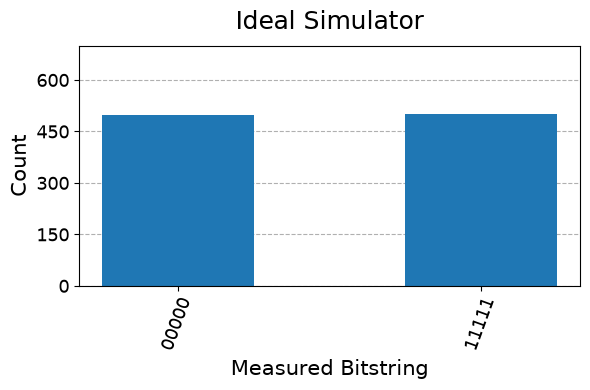

In [93]:
# Plot, save, and display the ideal results

fig, ax = plt.subplots(figsize=(6, 4))

plot_histogram(
    ideal_counts,
    ax=ax,
    bar_labels=False
)

ax.set_title(
    "Ideal Simulator",
    fontsize=18,
    pad=12
)

ax.set_xlabel("Measured Bitstring", fontsize=15)
ax.set_ylabel("Count", fontsize=15)

# Use a consistent scale across ideal and hardware results
ax.set_ylim(0, 0.7 * shots)

ax.tick_params(
    axis="x",
    labelsize=13
)

ax.tick_params(
    axis="y",
    labelsize=13
)

fig.tight_layout()

fig.savefig(
    f"GHZ_{n}_ideal.png",
    dpi=300,
    bbox_inches="tight"
)


## Run on IBM Quantum Hardware

We now run the same GHZ circuit on a real IBM quantum computer and compare its output with the ideal simulation.

#### Connect to IBM Quantum
Connect to the IBM Quantum service using previously saved account credentials.

In [94]:
# Import the IBM Quantum service
from qiskit_ibm_runtime import QiskitRuntimeService

# Connect using the saved account
service = QiskitRuntimeService()

print("Connected to IBM Quantum.")

Connected to IBM Quantum.


#### View Available Quantum Backends

List the operational IBM quantum backends available through the connected account.

In [124]:
# Get the available operational quantum backends

available_backends = service.backends(
    simulator=False,
    operational=True
)

# Print the backend names
print('Available IBM Quantum computers')
for backend in available_backends:
    print(f'    {backend.name}: {backend.num_qubits}-qubit device')

Available IBM Quantum computers
    ibm_fez: 156-qubit device
    ibm_marrakesh: 156-qubit device
    ibm_kingston: 156-qubit device


#### Select a Quantum Backend

A backend can be selected explicitly by name or automatically based on queue availability.

In [125]:
# Option 1: Select a backend by name
backend = service.backend('ibm_fez')

# Option 2: Select the least-busy operational backend
# backend = service.least_busy(
#     simulator=False,
#     operational=True)


print(f"Selected backend: {backend.name}")
print(f"Number of qubits: {backend.num_qubits}")
print(f"Pending jobs: {backend.status().pending_jobs}")

Selected backend: ibm_fez
Number of qubits: 156
Pending jobs: 3


#### Compile for the Selected Backend

Before execution, the circuit must be compiled for the selected backend. Compilation translates the circuit into supported instructions and maps its logical qubits to physical qubits.

We will study quantum compilation in the next lectures.

In [126]:
# Import the Qiskit transpiler
from qiskit import transpile


compiled_circuit = transpile(
    ghz_circuit,
    backend=backend,
    optimization_level=1
)

# compiled_circuit.draw(
#     "mpl",
#     idle_wires=False
# )

#### Submit the Circuit
Submit the compiled circuit to the selected IBM quantum backend. Save its job ID locally so the job can be retrieved later without keeping the notebook open.

In [98]:
# Create a sampler for the selected backend
ibm_sampler = Sampler(mode=backend)

# it may take some time to get the job executed 
# so we re-load the job that has been completed 
run_new_job=False

if run_new_job:
    # Submit the compiled circuit
    ibm_job = ibm_sampler.run(
        [compiled_circuit],
        shots=shots
    )

    # Get the job ID
    ibm_job_id = ibm_job.job_id()

    print(f"Backend: {backend.name}")
    print(f"Job ID: {ibm_job_id}")
    print(f"Job status: {ibm_job.status()}")

    # Save the job ID to a local file

    job_id_filename = f"GHZ_{n}_ibm_job_id.txt"

    with open(job_id_filename, "w") as file:
        file.write(ibm_job_id)

    print(f"Job ID saved to {job_id_filename}")
else:
    print('Will use existing saved job...')

Will use existing saved job...


#### Retrieve the Submitted Job
Load the saved job ID and use it to retrieve the submitted job. The retrieved job also provides information about the backend on which it ran.

In [99]:
# Load the saved job ID
job_id_filename = f"GHZ_{n}_ibm_job_id.txt"

# !!! you cannot retreive my job, even if you have access to the job ID :) 

with open(job_id_filename, "r") as file:
    ibm_job_id = file.read().strip()

print(f"Loaded job ID: {ibm_job_id}")

# Retrieve the job from IBM Quantum
retrieved_job = service.job(ibm_job_id)

# Retrieve the backend information from the job
job_backend = retrieved_job.backend()

print(f"Job ID: {retrieved_job.job_id()}")
print(f"Backend: {job_backend.name}")
print(f"Job status: {retrieved_job.status()}")

Loaded job ID: dac7ht51ierc738j8lh0
Job ID: dac7ht51ierc738j8lh0
Backend: ibm_fez
Job status: DONE


#### Retrieve and Visualize the Results
Retrieve the measurement outcomes from the completed IBM job and compare them with the ideal results.

In [100]:
# Retrieve the results

ibm_result = retrieved_job.result()
ibm_counts = ibm_result[0].data.meas.get_counts()

# Get the name of the backend used for execution
backend_name = retrieved_job.backend().name

print(f"Backend: {backend_name}")
print(ibm_counts)

Backend: ibm_fez
{'00000': 467, '11111': 459, '11101': 15, '01110': 3, '01000': 5, '00010': 18, '10111': 2, '10101': 4, '00001': 1, '11011': 3, '10000': 3, '01111': 12, '00110': 3, '11100': 1, '00100': 2, '01010': 1, '11110': 1}


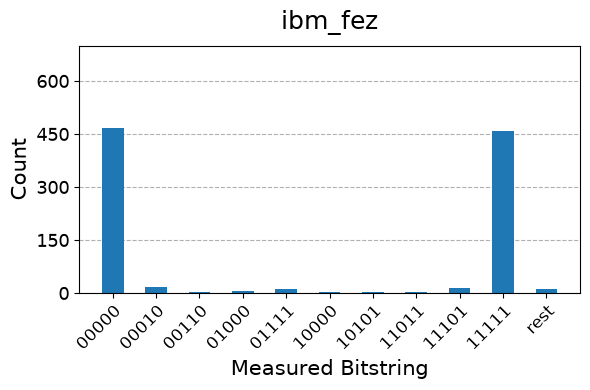

In [101]:
# Plot, save, and display the hardware results

fig, ax = plt.subplots(figsize=(6, 4))

plot_histogram(
    ibm_counts,
    ax=ax,
    number_to_keep=10,
    bar_labels=False
)

ax.set_title(
    backend_name,
    fontsize=18,
    pad=12
)

ax.set_xlabel("Measured Bitstring", fontsize=15)
ax.set_ylabel("Count", fontsize=15)

# Use the same scale as the ideal-results figure
ax.set_ylim(0, 0.7 * shots)

ax.tick_params(
    axis="x",
    labelsize=12,
    labelrotation=45
)

ax.tick_params(
    axis="y",
    labelsize=13
)

fig.tight_layout()

fig.savefig(
    f"GHZ_{n}_{backend_name}.png",
    dpi=300,
    bbox_inches="tight"
)



## Explore the Selected IBM Backend

An IBM backend provides two broad types of information:

1. **Device structure and capabilities:** Number of qubits, supported instructions, and physical connectivity.
2. **Characterization and calibration data:** Qubit properties, operation durations, and estimated error rates.

We first explore the device itself and then examine its reported characteristics.

### Device Overview

In [102]:
# Display general information about the selected backend
print(f"Backend name: {backend.name}")
print(f"Number of qubits: {backend.num_qubits}")
print(f"Backend version: {backend.backend_version}")
print(f"Maximum circuits per job: {backend.max_circuits}")
# print(f"System time resolution: {backend.dt} seconds")

Backend name: ibm_fez
Number of qubits: 156
Backend version: 1.3.37
Maximum circuits per job: None


#### Supported Instructions 

In [103]:
# Display the instructions supported by the backend
print("Supported instructions:")

for instruction in sorted(backend.operation_names):
    print(instruction)

Supported instructions:
cz
delay
id
if_else
measure
measure_2
measure_reset
measure_reset_2
reset
reset_2
rz
sx
x


#### Device Connectivity
The coupling map identifies the physical qubit pairs that support direct two-qubit interactions.

In [104]:
# Retrieve the coupling map
coupling_map = backend.coupling_map
coupling_links = coupling_map.get_edges()

print(f"Number of coupling links: {len(coupling_links)}")
print("First 20 coupling links:")

for link in coupling_links[:20]:
    print(link)

Number of coupling links: 352
First 20 coupling links:
(0, 1)
(1, 0)
(1, 2)
(2, 1)
(2, 3)
(3, 2)
(3, 4)
(3, 16)
(4, 3)
(4, 5)
(5, 4)
(5, 6)
(6, 5)
(6, 7)
(7, 6)
(7, 8)
(7, 17)
(8, 7)
(8, 9)
(9, 8)


#### Backend Target
The backend target describes which instructions can operate on which physical qubits. It also contains operation durations and estimated error rates used by the compiler.

In [105]:
# Retrieve the backend target
target = backend.target

print(f"Number of physical qubits: {target.num_qubits}")
print(f"Number of supported instruction types: {len(target.operation_names)}")

print("\nTarget instructions:")

for instruction in sorted(target.operation_names):
    print(instruction)

Number of physical qubits: 156
Number of supported instruction types: 13

Target instructions:
cz
delay
id
if_else
measure
measure_2
measure_reset
measure_reset_2
reset
reset_2
rz
sx
x


In [106]:
# Preview the physical-qubit assignments for each instruction
for instruction in sorted(target.operation_names):
    qubit_arguments = target.qargs_for_operation_name(instruction)

    if qubit_arguments is None:
        print(f"{instruction}: globally supported")
    else:
        print(
            f"{instruction}: "
            f"{len(qubit_arguments)} supported qubit assignment(s)"
        )

cz: 352 supported qubit assignment(s)
delay: 156 supported qubit assignment(s)
id: 156 supported qubit assignment(s)
if_else: globally supported
measure: 156 supported qubit assignment(s)
measure_2: 156 supported qubit assignment(s)
measure_reset: 156 supported qubit assignment(s)
measure_reset_2: 156 supported qubit assignment(s)
reset: 156 supported qubit assignment(s)
reset_2: 156 supported qubit assignment(s)
rz: 156 supported qubit assignment(s)
sx: 156 supported qubit assignment(s)
x: 156 supported qubit assignment(s)


## Device Characterization

Quantum devices are characterized through repeated calibration experiments. The reported values describe the device at a particular time and may vary across qubits and calibration cycles.

In [107]:
# Retrieve the latest reported backend properties
backend_properties = backend.properties(refresh=True)

print(f"Backend: {backend.name}")
print(f"Properties updated: {backend_properties.last_update_date}")

Backend: ibm_fez
Properties updated: 2026-09-03 10:07:19-06:00


#### available characterization data for qubit 

In [108]:
# Display the available characterization data for qubit 0
qubit_0_properties = backend_properties.qubit_property(0)

for property_name, property_data in qubit_0_properties.items():
    value, measured_at = property_data

    print(f"{property_name}: {value}")

T1: 3.0164885011816346e-05
T2: 2.6900441632785077e-05
readout_error: 0.0126953125
init_error: 0.0010782062161790952
prob_meas0_prep1: 0.023193359375
prob_meas1_prep0: 0.002197265625
readout_length: 1.66e-06


#### Initialization error for each qubit

In [109]:
initialization_errors = []
initialization_timestamps = []

for qubit in range(backend.num_qubits):
    qubit_properties = backend_properties.qubit_property(qubit)

    if "init_error" in qubit_properties:
        error, measured_at = qubit_properties["init_error"]

        initialization_errors.append(error)
        initialization_timestamps.append(measured_at)
    else:
        initialization_errors.append(np.nan)
        initialization_timestamps.append(None)


# Print the initialization errors

for qubit, error in enumerate(initialization_errors):
    if np.isnan(error):
        print(f"Qubit {qubit}: Not reported")
    else:
        print(f"Qubit {qubit}: {100 * error:.3f}%")

Qubit 0: 0.108%
Qubit 1: Not reported
Qubit 2: 0.182%
Qubit 3: Not reported
Qubit 4: 0.300%
Qubit 5: 0.223%
Qubit 6: 0.080%
Qubit 7: 0.825%
Qubit 8: 0.302%
Qubit 9: 0.058%
Qubit 10: 0.216%
Qubit 11: Not reported
Qubit 12: Not reported
Qubit 13: 0.260%
Qubit 14: 0.281%
Qubit 15: Not reported
Qubit 16: 0.212%
Qubit 17: 0.177%
Qubit 18: 0.100%
Qubit 19: 0.300%
Qubit 20: 0.406%
Qubit 21: 0.060%
Qubit 22: 0.080%
Qubit 23: 0.104%
Qubit 24: 0.391%
Qubit 25: 0.092%
Qubit 26: 0.080%
Qubit 27: 0.139%
Qubit 28: 0.141%
Qubit 29: 0.449%
Qubit 30: 0.362%
Qubit 31: 0.819%
Qubit 32: Not reported
Qubit 33: Not reported
Qubit 34: 0.492%
Qubit 35: Not reported
Qubit 36: 0.020%
Qubit 37: 0.123%
Qubit 38: 0.127%
Qubit 39: 0.486%
Qubit 40: 0.203%
Qubit 41: Not reported
Qubit 42: 0.349%
Qubit 43: Not reported
Qubit 44: 0.080%
Qubit 45: Not reported
Qubit 46: 0.101%
Qubit 47: Not reported
Qubit 48: 0.127%
Qubit 49: 0.629%
Qubit 50: 0.140%
Qubit 51: Not reported
Qubit 52: 0.129%
Qubit 53: Not reported
Qubit 54

#### Readout Error

Readout characterization estimates how often prepared states are assigned to the wrong classical outcomes.

- $P(1|0)$: A prepared $|0\rangle$ is reported as 1
- $P(0|1)$: A prepared $|1\rangle$ is reported as 0

In [110]:
# Retrieve readout characteristics for each physical qubit

prob_1_given_0 = []
prob_0_given_1 = []
readout_errors = []
readout_durations = []

for qubit in range(backend.num_qubits):
    qubit_properties = backend_properties.qubit_property(qubit)

    # Asymmetric misclassification probabilities
    p_1_0 = qubit_properties.get(
        "prob_meas1_prep0",
        (np.nan, None)
    )[0]

    p_0_1 = qubit_properties.get(
        "prob_meas0_prep1",
        (np.nan, None)
    )[0]

    # Average readout error and measurement duration
    measurement_properties = backend.target["measure"][(qubit,)]

    prob_1_given_0.append(p_1_0)
    prob_0_given_1.append(p_0_1)
    readout_errors.append(measurement_properties.error)
    readout_durations.append(measurement_properties.duration)


# Print the readout characteristics

print(
    f"{'Qubit':>5} "
    f"{'P(1|0)':>10} "
    f"{'P(0|1)':>10} "
    f"{'Avg. Error':>12} "
    f"{'Duration (µs)':>15}"
)

for qubit in range(backend.num_qubits):
    print(
        f"{qubit:>5} "
        f"{100 * prob_1_given_0[qubit]:>9.3f}% "
        f"{100 * prob_0_given_1[qubit]:>9.3f}% "
        f"{100 * readout_errors[qubit]:>11.3f}% "
        f"{1e6 * readout_durations[qubit]:>14.3f}"
    )

Qubit     P(1|0)     P(0|1)   Avg. Error   Duration (µs)
    0     0.220%     2.319%       1.270%          1.660
    1     0.977%     2.563%       1.770%          1.660
    2     0.366%     0.537%       0.452%          1.660
    3     0.952%     1.929%       1.440%          1.660
    4     0.464%     1.245%       0.854%          1.660
    5     0.562%     1.074%       0.818%          1.660
    6     0.195%     0.659%       0.427%          1.660
    7     1.685%     2.612%       2.148%          1.660
    8     0.537%     1.050%       0.793%          1.660
    9     5.396%     3.320%       4.358%          1.660
   10     0.122%     0.830%       0.476%          1.660
   11     3.711%     4.126%       3.918%          1.660
   12     1.709%     2.319%       2.014%          1.660
   13     1.245%     1.685%       1.465%          1.660
   14     0.464%     0.635%       0.549%          1.660
   15     2.051%     2.393%       2.222%          1.660
   16     0.415%     1.855%       1.062%       

#### Relaxation Time ($T_1$)
$T_1$ describes how quickly an excited qubit relaxes from $|1\rangle$ toward $|0\rangle$.

For a qubit initially in $|1\rangle$:

$$
P(1,t)=e^{-t/T_1}
$$

Larger $T_1$ values indicate that the qubit retains its excited-state population longer.

In [111]:
# Retrieve T1 for each physical qubit
t1_values = []

for qubit in range(backend.num_qubits):
    qubit_properties = backend.qubit_properties(qubit)

    if qubit_properties is None or qubit_properties.t1 is None:
        t1_values.append(np.nan)
    else:
        # Convert seconds to microseconds
        t1_values.append(qubit_properties.t1 * 1e6)

t1_values = np.array(t1_values)

In [112]:
# Summarize the T1 values

valid_t1 = np.isfinite(t1_values)

shortest_t1_qubit = np.nanargmin(t1_values)
longest_t1_qubit = np.nanargmax(t1_values)

print(f"Average T1: {np.nanmean(t1_values):.2f} µs")
print(
    f"Shortest T1: Qubit {shortest_t1_qubit}, "
    f"{t1_values[shortest_t1_qubit]:.2f} µs"
)
print(
    f"Longest T1: Qubit {longest_t1_qubit}, "
    f"{t1_values[longest_t1_qubit]:.2f} µs"
)

Average T1: 132.55 µs
Shortest T1: Qubit 72, 23.40 µs
Longest T1: Qubit 13, 304.99 µs


#### Dephasing Time ($T_2$)

$T_2$ describes how quickly a qubit loses loses phase coherence.

$$
C(t)=C(0)e^{-t/T_2}
$$

Larger $T_2$ values indicate that the qubit preserves phase information longer.

In [113]:
# Retrieve T2 for each physical qubit

t2_values = []

for qubit in range(backend.num_qubits):
    qubit_properties = backend.qubit_properties(qubit)

    if qubit_properties is None or qubit_properties.t2 is None:
        t2_values.append(np.nan)
    else:
        # Convert seconds to microseconds
        t2_values.append(qubit_properties.t2 * 1e6)

t2_values = np.array(t2_values)

In [114]:
# Summarize the T2 values

shortest_t2_qubit = np.nanargmin(t2_values)
longest_t2_qubit = np.nanargmax(t2_values)

print(f"Average T2: {np.nanmean(t2_values):.2f} µs")
print(
    f"Shortest T2: Qubit {shortest_t2_qubit}, "
    f"{t2_values[shortest_t2_qubit]:.2f} µs"
)
print(
    f"Longest T2: Qubit {longest_t2_qubit}, "
    f"{t2_values[longest_t2_qubit]:.2f} µs"
)

Average T2: 99.53 µs
Shortest T2: Qubit 149, 5.39 µs
Longest T2: Qubit 88, 259.37 µs


#### Gate Errors and Durations

The backend target reports an estimated error rate and duration for each physical gate implementation.

Gate characteristics may vary across:

- Gate types
- Physical qubits
- Two-qubit coupling links

In [115]:
# Collect one- and two-qubit gate characteristics

gate_records = []

excluded_instructions = {
    "measure",
    "reset",
    "delay",
    "barrier"
}

for gate_name in sorted(target.operation_names):
    if gate_name in excluded_instructions:
        continue

    qubit_arguments = target.qargs_for_operation_name(gate_name)

    # Skip globally defined instructions without explicit qubit assignments
    if qubit_arguments is None:
        continue

    for qubits_used in qubit_arguments:
        if len(qubits_used) not in (1, 2):
            continue

        gate_properties = target[gate_name][qubits_used]

        if gate_properties is None:
            continue

        gate_records.append(
            {
                "gate": gate_name,
                "qubits": qubits_used,
                "num_qubits": len(qubits_used),
                "error": gate_properties.error,
                "duration": gate_properties.duration
            }
        )

In [116]:
# Display the discovered physical gate types

one_qubit_gates = sorted({
    record["gate"]
    for record in gate_records
    if record["num_qubits"] == 1
})

two_qubit_gates = sorted({
    record["gate"]
    for record in gate_records
    if record["num_qubits"] == 2
})

print("One-qubit gates:", one_qubit_gates)
print("Two-qubit gates:", two_qubit_gates)

One-qubit gates: ['id', 'measure_2', 'measure_reset', 'measure_reset_2', 'reset_2', 'rz', 'sx', 'x']
Two-qubit gates: ['cz']


In [117]:
# Summarize error and duration by gate type

print(
    f"{'Gate':>10} "
    f"{'Qubits':>8} "
    f"{'Instances':>10} "
    f"{'Median Error':>15} "
    f"{'Median Duration':>18}"
)

for gate_name in sorted({
    record["gate"]
    for record in gate_records
}):
    records = [
        record
        for record in gate_records
        if record["gate"] == gate_name
    ]

    errors = [
        record["error"]
        for record in records
        if record["error"] is not None
    ]

    durations = [
        record["duration"]
        for record in records
        if record["duration"] is not None
    ]

    gate_size = records[0]["num_qubits"]

    median_error = (
        100 * np.median(errors)
        if errors else np.nan
    )

    median_duration = (
        1e9 * np.median(durations)
        if durations else np.nan
    )

    print(
        f"{gate_name:>10} "
        f"{gate_size:>8} "
        f"{len(records):>10} "
        f"{median_error:>14.4f}% "
        f"{median_duration:>15.2f} ns"
    )

      Gate   Qubits  Instances    Median Error    Median Duration
        cz        2        352         0.2846%           68.00 ns
        id        1        156         0.0313%           24.00 ns
 measure_2        1        156         1.4038%         1340.00 ns
measure_reset        1        156            nan%         1684.00 ns
measure_reset_2        1        156            nan%         1364.00 ns
   reset_2        1        156            nan%         1364.00 ns
        rz        1        156         0.0000%            0.00 ns
        sx        1        156         0.0313%           24.00 ns
         x        1        156         0.0313%           24.00 ns


#### Qubit Frequencies and Coupling Links

Superconducting qubits operate at specific frequencies. Qubits with nearby frequencies may be more susceptible to unwanted interactions and frequency collisions.
Frequency proximity is only a possible indicator of crosstalk, not a direct crosstalk measurement.

In [118]:
# Retrieve the operating frequency of each physical qubit

qubit_frequencies = []

for qubit in range(backend.num_qubits):
    qubit_properties = backend.qubit_properties(qubit)

    if (
        qubit_properties is None
        or qubit_properties.frequency is None
    ):
        qubit_frequencies.append(np.nan)
    else:
        # Convert Hz to GHz
        qubit_frequencies.append(
            qubit_properties.frequency / 1e9
        )

qubit_frequencies = np.array(qubit_frequencies) 


In [119]:
# Print the qubit frequencies

for qubit, frequency in enumerate(qubit_frequencies):
    if np.isnan(frequency):
        print(f"Qubit {qubit}: Not reported")
    else:
        print(f"Qubit {qubit}: {frequency:.4f} GHz")

Qubit 0: Not reported
Qubit 1: Not reported
Qubit 2: Not reported
Qubit 3: Not reported
Qubit 4: Not reported
Qubit 5: Not reported
Qubit 6: Not reported
Qubit 7: Not reported
Qubit 8: Not reported
Qubit 9: Not reported
Qubit 10: Not reported
Qubit 11: Not reported
Qubit 12: Not reported
Qubit 13: Not reported
Qubit 14: Not reported
Qubit 15: Not reported
Qubit 16: Not reported
Qubit 17: Not reported
Qubit 18: Not reported
Qubit 19: Not reported
Qubit 20: Not reported
Qubit 21: Not reported
Qubit 22: Not reported
Qubit 23: Not reported
Qubit 24: Not reported
Qubit 25: Not reported
Qubit 26: Not reported
Qubit 27: Not reported
Qubit 28: Not reported
Qubit 29: Not reported
Qubit 30: Not reported
Qubit 31: Not reported
Qubit 32: Not reported
Qubit 33: Not reported
Qubit 34: Not reported
Qubit 35: Not reported
Qubit 36: Not reported
Qubit 37: Not reported
Qubit 38: Not reported
Qubit 39: Not reported
Qubit 40: Not reported
Qubit 41: Not reported
Qubit 42: Not reported
Qubit 43: Not reporte

## IBM Backend-Derived Noisy Simulation

We now create a noisy simulator from the selected IBM backend and run the same GHZ circuit locally.

#### Creating Noisy Simulator 
The simulator automatically uses a simplified noise model derived from the backend characteristics. It approximates the hardware but does not capture every physical error.

In [80]:
# Create a noisy simulator from the selected IBM backend
noisy_simulator = AerSimulator.from_backend(backend)

print(f"Source backend: {backend.name}")
print(f"Noisy simulator: {noisy_simulator.name}")

Source backend: ibm_fez
Noisy simulator: aer_simulator_from(ibm_fez)


#### Compile the Circuit

The circuit must be compiled for the instructions and connectivity represented by the noisy simulator.

In [81]:
# Compile the original GHZ circuit for the noisy simulator
noisy_compiled_circuit = transpile(
    ghz_circuit,
    backend=noisy_simulator,
    optimization_level=1
)


#### Run the Noisy Simulation

Execute the compiled GHZ circuit using the backend-derived noisy simulator.

In [82]:
# Create a sampler using the noisy simulator
noisy_sampler = Sampler(mode=noisy_simulator)

# Run the compiled circuit
noisy_job = noisy_sampler.run(
    [noisy_compiled_circuit],
    shots=shots
)

# Retrieve the results
noisy_result = noisy_job.result()
noisy_counts = noisy_result[0].data.meas.get_counts()

print(noisy_counts)

{'11111': 468, '00000': 479, '00100': 3, '00010': 3, '01111': 3, '01010': 6, '11011': 3, '10000': 7, '00001': 4, '01000': 3, '10111': 5, '01110': 2, '11110': 5, '10001': 2, '11101': 5, '01011': 1, '11001': 1}


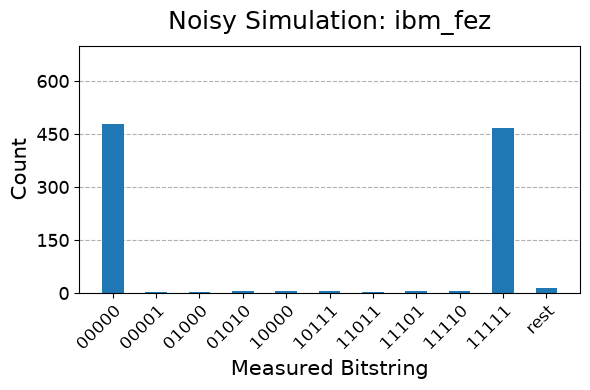

In [83]:
# Plot, save, and display the noisy-simulation results

fig, ax = plt.subplots(figsize=(6, 4))

plot_histogram(
    noisy_counts,
    ax=ax,
    number_to_keep=10,
    bar_labels=False
)

ax.set_title(
    f"Noisy Simulation: {backend.name}",
    fontsize=18,
    pad=12
)

ax.set_xlabel("Measured Bitstring", fontsize=15)
ax.set_ylabel("Count", fontsize=15)

ax.set_ylim(0, 0.7 * shots)

ax.tick_params(
    axis="x",
    labelsize=12,
    labelrotation=45
)

ax.tick_params(
    axis="y",
    labelsize=13
)

fig.tight_layout()

fig.savefig(
    f"GHZ_{n}_{backend.name}_noisy.png",
    dpi=300,
    bbox_inches="tight"
)


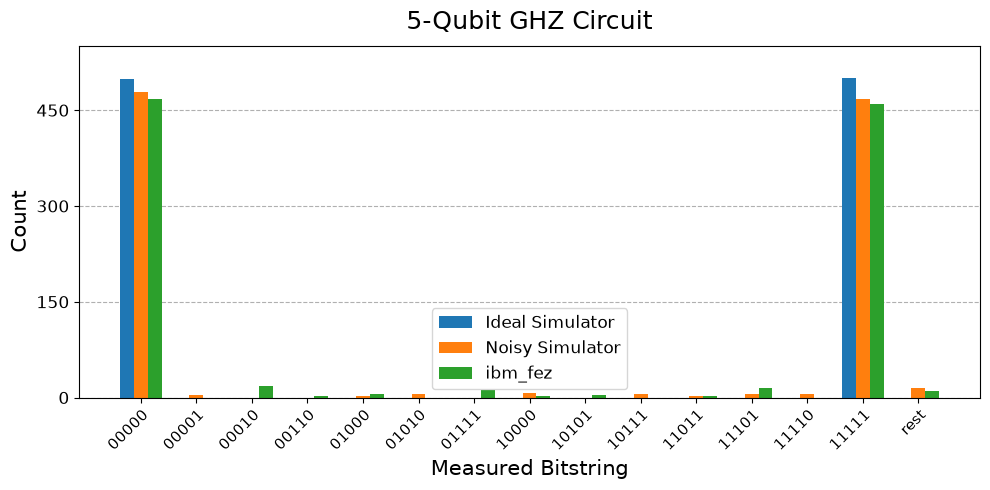

In [85]:
# Compare ideal, noisy, and hardware results
fig, ax = plt.subplots(figsize=(10, 5))

plot_histogram(
    [
        ideal_counts,
        noisy_counts,
        ibm_counts
    ],
    legend=[
        "Ideal Simulator",
        "Noisy Simulator",
        backend_name
    ],
    number_to_keep=10,
    bar_labels=False,
    ax=ax
)

ax.set_title(
    f"{n}-Qubit GHZ Circuit",
    fontsize=18,
    pad=12
)

ax.set_xlabel("Measured Bitstring", fontsize=15)
ax.set_ylabel("Count", fontsize=15)

ax.tick_params(
    axis="x",
    labelsize=11,
    labelrotation=45
)

ax.tick_params(
    axis="y",
    labelsize=12
)

ax.legend(fontsize=12)

fig.tight_layout()

fig.savefig(
    f"GHZ_{n}_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


## Reliability Metrics

We use circuit-based metrics before execution and outcome-based metrics after execution.

#### Circuit-Based Metrics

Circuit depth and gate counts can be extracted from the compiled circuit without running it.

In [120]:
# Extract circuit metrics

def get_circuit_metrics(circuit):
    one_qubit_gates = 0
    two_qubit_gates = 0
    measurements = 0

    for instruction in circuit.data:
        operation = instruction.operation

        if operation.name == "measure":
            measurements += 1

        elif operation.name not in {"barrier", "delay"}:
            if operation.num_qubits == 1:
                one_qubit_gates += 1

            elif operation.num_qubits == 2:
                two_qubit_gates += 1

    return {
        "Circuit Depth": circuit.depth(),
        "Total Gates": one_qubit_gates + two_qubit_gates,
        "One-Qubit Gates": one_qubit_gates,
        "Two-Qubit Gates": two_qubit_gates,
        "Measurements": measurements
    }


# Get metrics for both circuits

abstract_metrics = get_circuit_metrics(ghz_circuit)
compiled_metrics = get_circuit_metrics(compiled_circuit)


# Print the comparison

print(f"{'Metric':<20}\tAbstract\tCompiled")
print("-" * 48)

for metric in abstract_metrics:
    print(
        f"{metric:<20}\t"
        f"{abstract_metrics[metric]}\t\t"
        f"{compiled_metrics[metric]}"
    )

Metric              	Abstract	Compiled
------------------------------------------------
Circuit Depth       	6		18
Total Gates         	5		39
One-Qubit Gates     	1		32
Two-Qubit Gates     	4		7
Measurements        	5		5


#### Total Variation Distance
Total variation distance measures the difference between the ideal and hardware output distributions:

$$
\mathrm{TVD}(P,Q)
=
\frac{1}{2}
\sum_x
|P(x)-Q(x)|
$$

A smaller TVD indicates that the hardware result is closer to the ideal result.

In [88]:
# Convert counts to probabilities

ideal_total = sum(ideal_counts.values())
hardware_total = sum(ibm_counts.values())

ideal_probabilities = {
    outcome: count / ideal_total
    for outcome, count in ideal_counts.items()
}

hardware_probabilities = {
    outcome: count / hardware_total
    for outcome, count in ibm_counts.items()
}


# Include every outcome observed in either result

all_outcomes = (
    set(ideal_probabilities)
    | set(hardware_probabilities)
)


# Calculate TVD

tvd = 0.5 * sum(
    abs(
        ideal_probabilities.get(outcome, 0)
        - hardware_probabilities.get(outcome, 0)
    )
    for outcome in all_outcomes
)

print(f"Ideal vs. hardware TVD: {tvd:.4f}")

Ideal vs. hardware TVD: 0.0740
